# PathSnap: Exploratory Data Analysis & Preprocessing (Phase 1)
**Course:** UE24CS352A - Machine Learning | PES University  
**Project:** PathSnap - Distributed Map-Matching & Route Reconstruction  
---
### Purpose of this Notebook
This notebook performs the comprehensive Phase 1 Exploratory Data Analysis (EDA) on the PathSnap dataset as outlined in `Dataset Exploration.pdf` and `Deliverables.pdf`:
1. Dataset inventory and partition verification.
2. Detailed inspection of `.track`, `.nodes`, `.arcs`, and `.route` files.
3. Anomaly detection: missing values, coordinate validity, sampling jitter, and gaps.
4. Vehicle dynamics and Haversine speed profiling.
5. Road network topology and ground-truth route continuity checks.
6. Mandatory interactive geographical visualization using Folium.

In [1]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium import plugins

sns.set_theme(style='whitegrid')
print('Libraries successfully imported!')

Libraries successfully imported!


## 1. Dataset Inventory & Partition Overview
We load the empirical summaries generated across all 80 training trips and 10 student testing trips.

In [2]:
train_summary = pd.read_csv('reports/train_trips_summary.csv')
test_summary = pd.read_csv('reports/test_trips_summary.csv')

print(f'=== Training Set: {len(train_summary)} trips ===')
print(f'Total GPS Observations: {train_summary["gps_points"].sum():,}')
print(f'Avg GPS Observations per Trip: {train_summary["gps_points"].mean():.1f} (+/- {train_summary["gps_points"].std():.1f})')
print(f'Avg Trajectory Distance: {train_summary["track_distance_km"].mean():.2f} km')
print(f'Avg Route Continuity: {train_summary["route_continuity_pct"].mean():.2f}%')
print(f'Nominal 1 Hz Steps: {train_summary["pct_exact_1s"].mean():.2f}%')

train_summary.head()

=== Training Set: 80 trips ===
Total GPS Observations: 208,417
Avg GPS Observations per Trip: 2605.2 (+/- 3312.3)
Avg Trajectory Distance: 37.23 km
Avg Route Continuity: 99.94%
Nominal 1 Hz Steps: 93.83%


,partition,trip_id,gps_points,duration_s,track_distance_km,avg_speed_kmh,max_speed_kmh,pct_exact_1s,max_time_gap_s,gaps_gt_2s,network_nodes,network_arcs,route_steps,route_continuity_pct,min_lon,max_lon,min_lat,max_lat,bbox_span_km
0,train,1,1315,1357.000,50.186,136.88,260.72,98.10,16.0,4,88809,165790,525,100.00,8.570524,8.647860,49.844053,50.211882,41.272
1,train,2,7243,8933.156,55.872,27.29,134.19,97.46,160.0,124,7936,16139,262,99.62,10.999961,11.050902,47.658344,47.695459,5.619
2,train,3,821,823.000,8.420,36.84,104.87,99.63,2.0,0,9138,18028,79,100.00,37.154202,37.201595,55.977135,56.007585,4.489
3,train,4,1064,5217.000,27.891,25.84,104.98,53.81,51.0,432,7350,15499,320,100.00,12.342280,12.459615,52.590308,52.718960,16.349
4,train,5,1045,1044.000,31.326,108.02,229.47,100.00,1.0,0,898,1579,105,100.00,35.485577,35.544315,49.357581,49.613085,28.726


## 2. Inspecting Sample Trip Structure (Trip 00000000)
Let us inspect the four constituent files for student test trip `00000000`.

In [3]:
candidates = [
    os.path.join('..', 'Student folder', 'Student folder', 'student_test', '00000000'),
    os.path.join('Student folder', 'Student folder', 'student_test', '00000000'),
    os.path.join('..', 'student_test', '00000000'),
    os.path.join('student_test', '00000000')
]
trip_dir = next((c for c in candidates if os.path.exists(c)), candidates[0])

for ext in ['track', 'nodes', 'arcs', 'route']:
    fpath = os.path.join(trip_dir, f'00000000.{ext}')
    if os.path.exists(fpath):
        with open(fpath) as f:
            lines = [f.readline().strip() for _ in range(5)]
        print(f'--- 00000000.{ext} (First 5 lines) ---')
        for l in lines:
            print(l)
        print()


--- 00000000.track (First 5 lines) ---
54.963519	56.251559	1.000000
54.963143	56.251523	2.000000
54.962942	56.251470	3.000000
54.962730	56.251532	4.000000
54.962397	56.251549	5.000000
--- 00000000.nodes (First 5 lines) ---
54.335879	56.117280
54.256444	56.081855
54.257354	56.081634
54.258239	56.081233
54.258685	56.083573
--- 00000000.arcs (First 5 lines) ---
0	2433
0	2475
0	2480
1	2
1	8408
--- 00000000.route (First 5 lines) ---
17630
17633
211
17638
17645



## 3. Data Quality & Anomaly Analysis
We verify whether there are missing values, invalid coordinates, or large time gaps.

In [4]:
print('Missing values in Train Summary:')
print(train_summary.isnull().sum())

invalid_lon = ((train_summary['min_lon'] < -180) | (train_summary['max_lon'] > 180)).sum()
invalid_lat = ((train_summary['min_lat'] < -90) | (train_summary['max_lat'] > 90)).sum()
print(f'Invalid Lon Trips: {invalid_lon}, Invalid Lat Trips: {invalid_lat}')

gap_trips = train_summary[train_summary['gaps_gt_2s'] > 0]
print(f'Trips with GPS Gaps > 2s: {len(gap_trips)} of {len(train_summary)}')

Missing values in Train Summary:
partition               0
trip_id                 0
gps_points              0
duration_s              0
track_distance_km       0
avg_speed_kmh           0
max_speed_kmh           0
pct_exact_1s            0
max_time_gap_s          0
gaps_gt_2s              0
network_nodes           0
network_arcs            0
route_steps             0
route_continuity_pct    0
min_lon                 0
max_lon                 0
min_lat                 0
max_lat                 0
bbox_span_km            0
dtype: int64
Invalid Lon Trips: 0, Invalid Lat Trips: 0
Trips with GPS Gaps > 2s: 50 of 80


## 4. Sampling Interval & Vehicle Speed Distribution
We visualize the distribution of average speeds and the fidelity of 1-second timestamps.

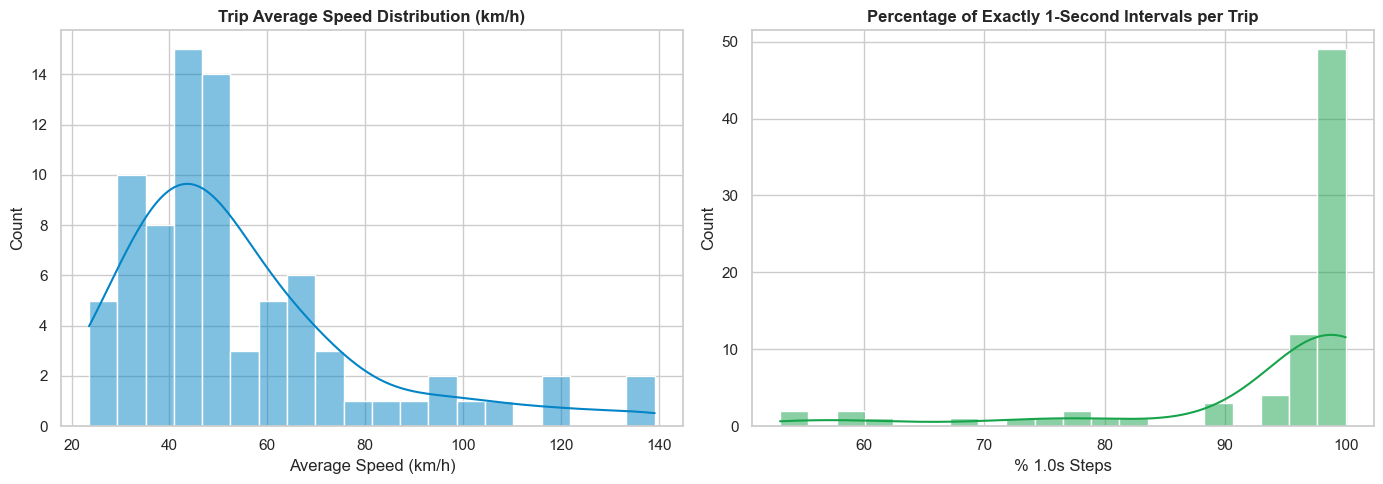

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_summary['avg_speed_kmh'], bins=20, kde=True, ax=axes[0], color='#0284c7')
axes[0].set_title('Trip Average Speed Distribution (km/h)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Average Speed (km/h)')

sns.histplot(train_summary['pct_exact_1s'], bins=20, kde=True, ax=axes[1], color='#16a34a')
axes[1].set_title('Percentage of Exactly 1-Second Intervals per Trip', fontsize=12, fontweight='bold')
axes[1].set_xlabel('% 1.0s Steps')
plt.tight_layout()
plt.show()

## 5. Interactive Folium Visualization
Rendering the interactive map showing GPS trajectory, road network graph, and ground truth route.

In [6]:
import IPython.display as display
display.IFrame('visualizations/folium_trip_00000000.html', width='100%', height=550)

<IPython.lib.display.IFrame at 0x...>